# 07 — HONTECH HT9046-MX Server Shadow Replay

## tl;dr

Phase 7 replay รุ่น `hp180` ใช้ `ARX-Ridge__seed_13` ซึ่งยังชนะ **inner temporal validation** หลังเปลี่ยน field rule เป็นช่วง 180–230 psi. Threshold 7.6507 มาจาก calibration block ในอดีต และใช้ persistence 3 หน้าต่างต่อเนื่องที่ cadence 5 นาที

- Primary outer replay: 131,853 score rows, raw flag rate 0.394%, persistent alerts 36 ครั้ง หรือ 0.456 alerts ต่อ machine-day
- Restart/checkpoint replay ให้ผลตรงกับ one-shot replay
- MX-080 Module 6 มี raw deviation ก่อน transition ที่มองเห็น และเปิด persistent alert เวลา 12:35 วันที่ 7 ก.ย.; เวลานี้เป็น descriptive replay timing ไม่ใช่ validated fault lead time
- MX-080 raw flag rate ก่อน transition เท่ากับ 3.0% (100 scored rows) และหลัง transition เท่ากับ 100% (139 scored rows); เป็น sensitivity evidence ของเหตุการณ์เดียว ไม่ใช่ accuracy
- Reference ของ MX-080 มีเพียง 4 วัน จึงเป็น `INCIDENT_REPLAY_ONLY_INSUFFICIENT_FOR_PRODUCTION`
- ผลยังเป็น anomaly-screening evidence ไม่ใช่ fault accuracy และยัง deploy production ไม่ได้เพราะไม่มี rollback target/alert budget/confirmed labels

## Context & Methods

### Key Assumptions

- ไม่เลือก model, feature, threshold หรือ persistence จาก outer test หรือ MX-080
- Primary replay ใช้ qualified minute stream แล้ว score ทุก 5 นาทีตามลำดับเวลา
- MX-080 ใช้ Pressure รายวินาทีสร้าง minute stream และ 30/120-second ring-buffer features; ไม่ใช้ MessageLog เป็น feature
- Missing, stale, out-of-order, wrong feature version/order และ checksum mismatch ต้อง fail closed เป็น data/contract status ไม่ใช่ equipment alert
- `Busy_n` ไม่ใช่ compressor-run proof; ใช้ state gate ตาม Data Contract ปัจจุบันเท่านั้น
- Timezone เป็น Asia/Bangkok ตามบริบท แต่ source ไม่ encode timezone
- Persistence 3 × 5 นาทีเป็น pilot policy ที่ยังต้องผ่าน operations alert-budget review
- `Hp_2nd < 180 psi` เป็น low-side screening feature; `Hp_2nd > 230 psi` ยังถูกจับได้ผ่าน local/multivariate deviation แต่ไม่ถูกแปลเป็น undercharge หรือปัญหาระบบน้ำอัตโนมัติ

## Data

### 1. Load project and dependencies

In [1]:
import importlib.util
import json
import os
import subprocess
import sys
from pathlib import Path

required = {
    'pandas': 'pandas>=2', 'numpy': 'numpy>=1.26', 'polars': 'polars>=1',
    'sklearn': 'scikit-learn>=1.4', 'joblib': 'joblib>=1.3',
    'matplotlib': 'matplotlib>=3.8', 'pyarrow': 'pyarrow>=15'
}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import pandas as pd
from IPython.display import Image, display

override = os.environ.get('HT9046MX_PROJECT_ROOT', '').strip()
candidates = [Path(override)] if override else []
candidates += [Path.cwd(), Path.cwd().parent, Path('/content/OPERATION_P'), Path('/content/drive/MyDrive/OPERATION_P')]
PROJECT_ROOT = next((path.resolve() for path in candidates if (path / 'README_System.md').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('ไม่พบ README_System.md — mount Google Drive หรือกำหนด HT9046MX_PROJECT_ROOT')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

OUTPUT_ROOT = PROJECT_ROOT / 'notebooks' / 'outputs' / 'ht9046mx_phase7_shadow_replay_v2_hp180'
print('Project:', PROJECT_ROOT)
print('Output:', OUTPUT_ROOT)

Project: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P
Output: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_phase7_shadow_replay_v2_hp180


### 2. Run deterministic replay from locked artifacts

In [2]:
from notebooks.support.phase7_shadow_replay import ReplayConfig, run_shadow_replay

result = run_shadow_replay(ReplayConfig(PROJECT_ROOT, OUTPUT_ROOT))
summary = result['summary']
display(pd.Series({
    'status': summary['status'],
    'model': summary['selected_model'],
    'threshold': summary['threshold'],
    'persistence': summary['persistence'],
    'primary_rows': summary['primary']['scored_rows'],
    'primary_raw_flag_pct': summary['primary']['raw_flag_rate_pct'],
    'persistent_alerts': summary['primary']['persistent_alerts'],
    'alerts_per_machine_day': summary['primary']['alerts_per_machine_day'],
    'mx080_first_detection': summary['mx080']['first_persistent_detection'],
    'mx080_delay_minutes': summary['mx080']['detection_delay_from_122320_minutes'],
}))

status                                       PASS_WITH_PRODUCTION_BLOCKERS
model                                                   ARX-Ridge__seed_13
threshold                                                         7.650716
persistence               3 consecutive qualified 5-minute scoring windows
primary_rows                                                        131853
primary_raw_flag_pct                                               0.39362
persistent_alerts                                                       36
alerts_per_machine_day                                            0.455696
mx080_first_detection                                  2026-09-07 12:35:00
mx080_delay_minutes                                              11.666667
dtype: object

## Results

### 3. Primary outer replay — alert burden

กราฟนี้ใช้ตรวจภาระ Alert และความต่างระหว่างเครื่อง ไม่ใช่ precision/recall. ค่าเครื่องสูงผิดกลุ่มต้องถูกตรวจเป็น state/profile mismatch ก่อนเรียก equipment problem.

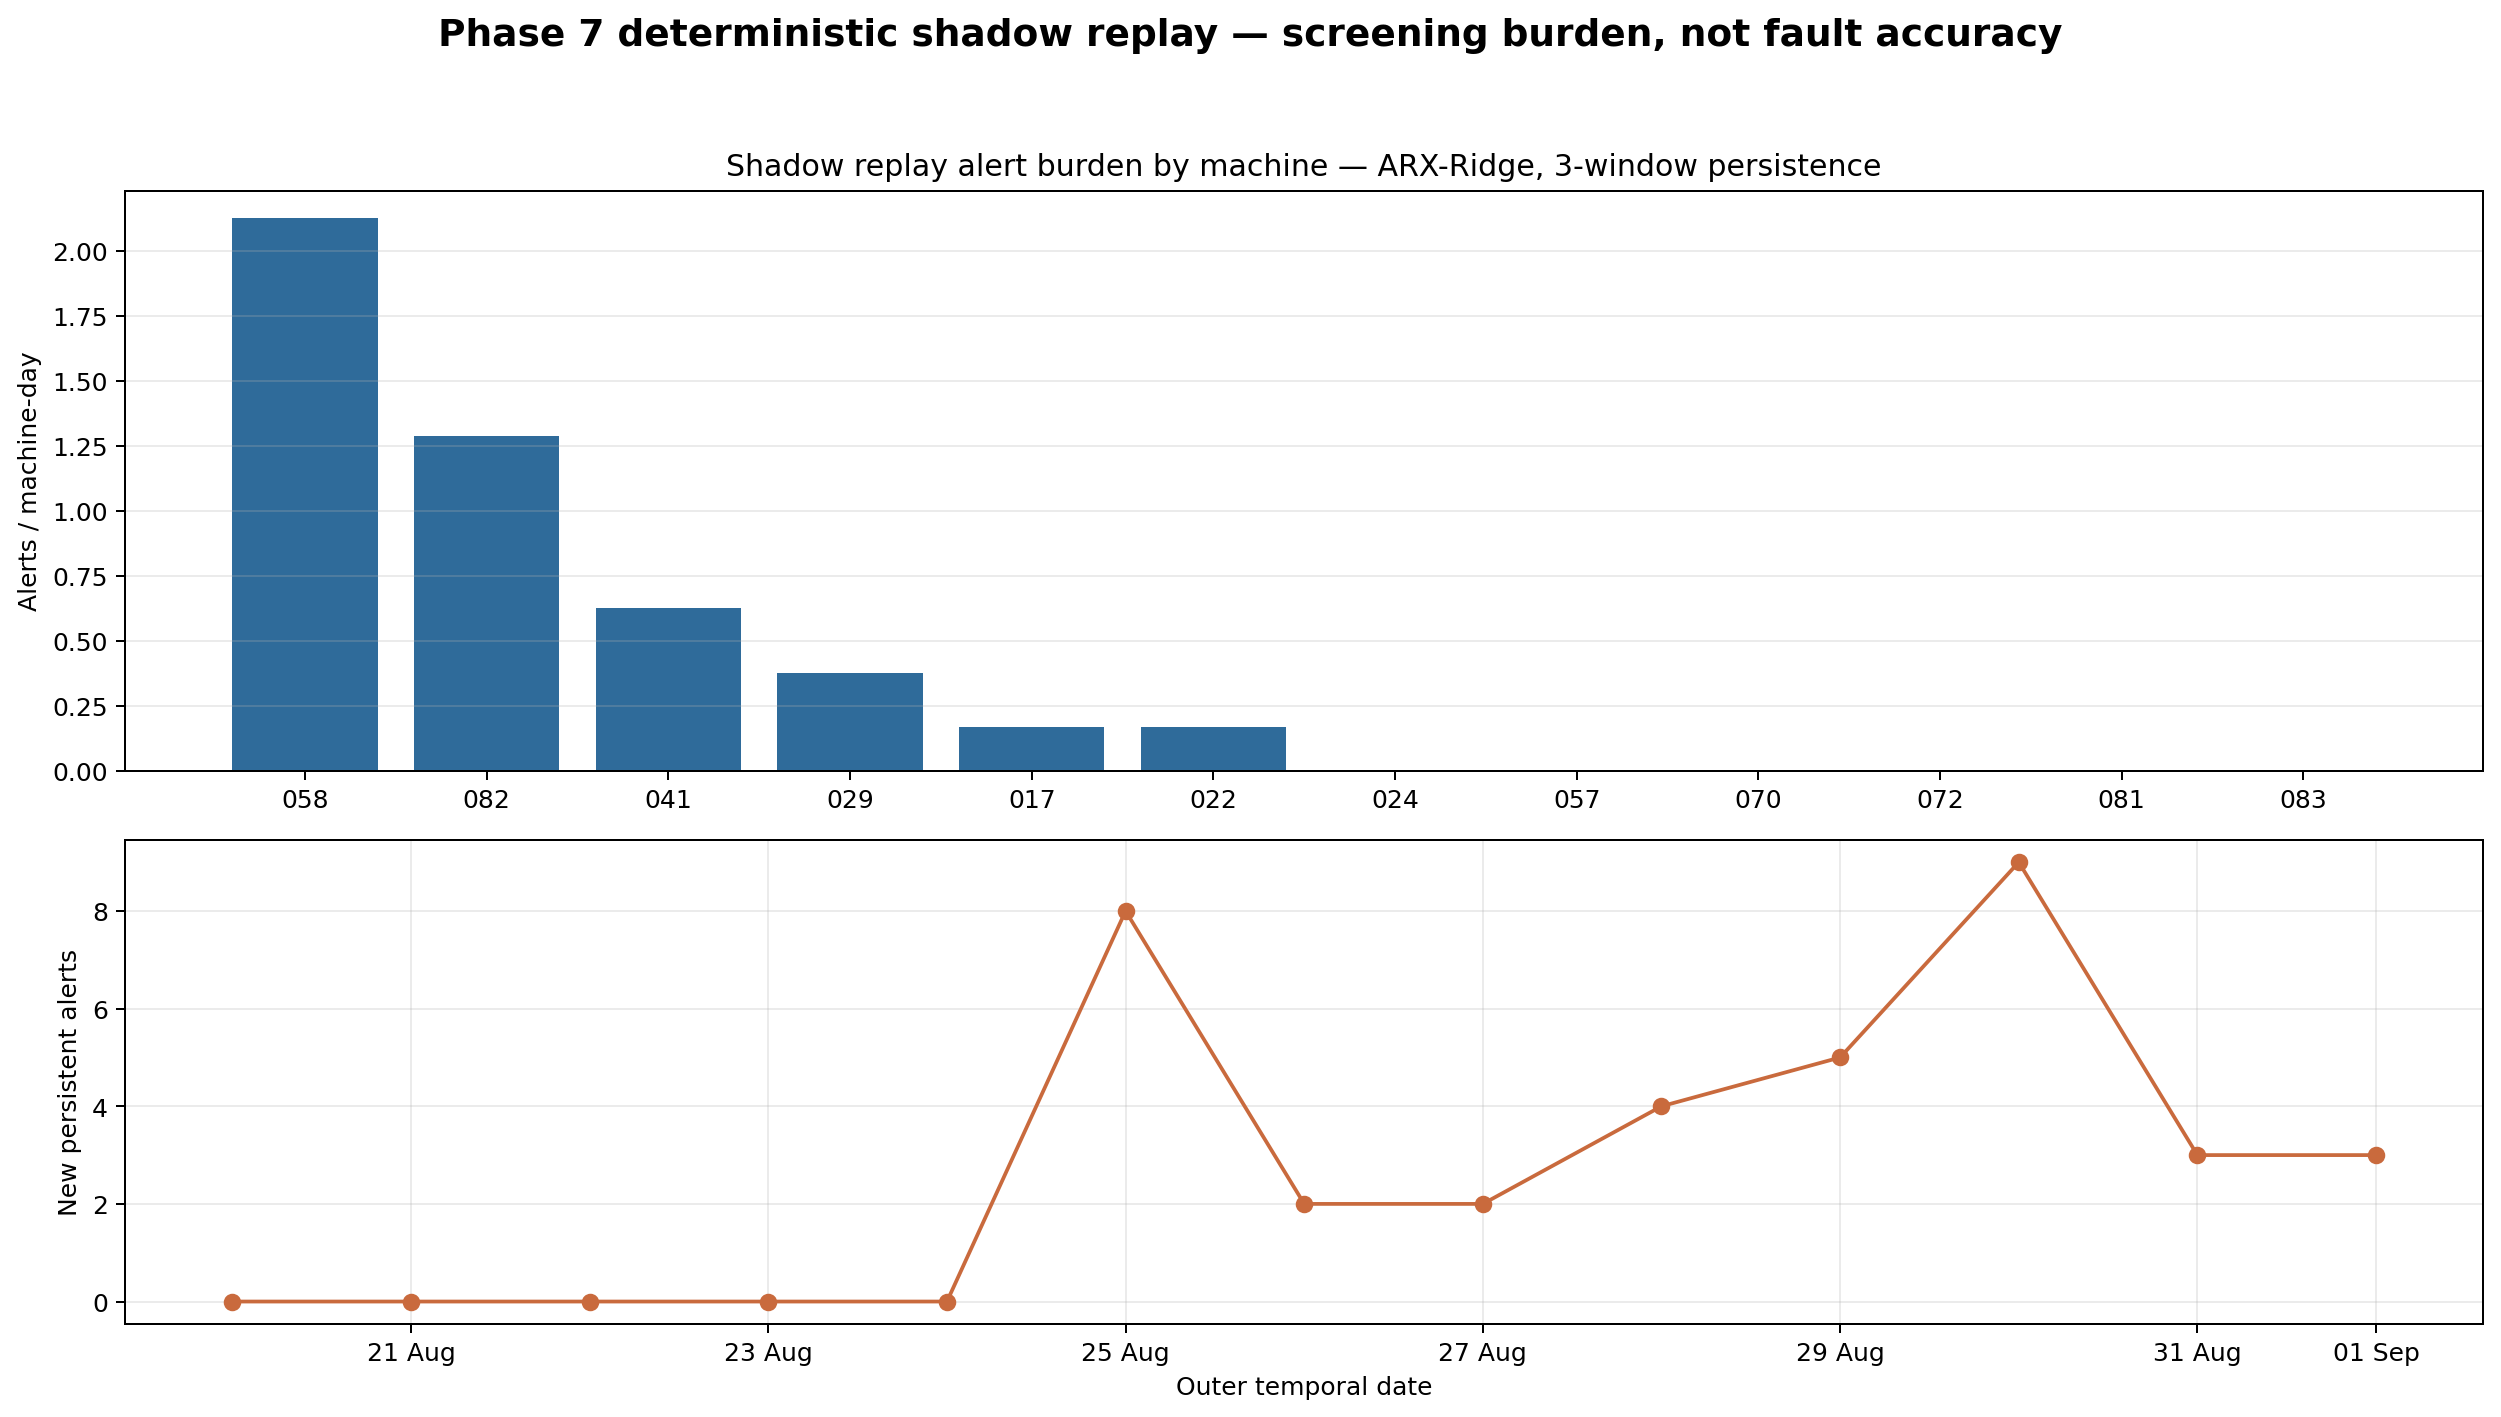

In [3]:
display(Image(filename=summary['figures']['primary']))

### 4. Replay summary by machine

In [4]:
display(result['primary_by_machine'].sort_values('alerts_per_machine_day', ascending=False).round(4))
display(result['primary_episodes'].head(20).round(4))

,machine_number,scored_rows,raw_flag_rate_pct,persistent_rows,alerts,scored_days,alerts_per_machine_day
6,058,16269,1.1187,105,17,8,2.1250
10,082,9046,2.3436,183,9,7,1.2857
4,041,15630,0.3071,8,5,8,0.6250
3,029,10602,0.2264,4,3,8,0.3750
0,017,10345,0.1837,11,1,6,0.1667
1,022,8934,0.1903,10,1,6,0.1667
2,024,8029,0.0498,0,0,5,0.0000
5,057,9822,0.0713,0,0,6,0.0000
7,070,12930,0.0077,0,0,7,0.0000
8,072,10501,0.0095,0,0,5,0.0000


,machine_number,module,sv,episode_start,detected_at,detection_delay_minutes,score,threshold
0,058,6,Off,2026-08-25 05:25:00,2026-08-25 05:35:00,10.0,7.7231,7.6507
1,058,6,Off,2026-08-25 05:55:00,2026-08-25 06:05:00,10.0,7.7794,7.6507
2,058,6,Off,2026-08-25 06:40:00,2026-08-25 06:50:00,10.0,7.6830,7.6507
3,058,6,Off,2026-08-25 07:30:00,2026-08-25 07:40:00,10.0,7.7462,7.6507
4,058,6,Off,2026-08-25 08:10:00,2026-08-25 08:20:00,10.0,7.7734,7.6507
5,058,6,Off,2026-08-25 09:05:00,2026-08-25 09:15:00,10.0,7.6701,7.6507
6,058,6,Off,2026-08-25 11:05:00,2026-08-25 11:15:00,10.0,7.7054,7.6507
7,058,6,Off,2026-08-25 12:15:00,2026-08-25 12:25:00,10.0,7.7859,7.6507
8,029,1,Off,2026-08-26 10:40:00,2026-08-26 10:50:00,10.0,13.6559,7.6507
9,029,4,Off,2026-08-26 10:40:00,2026-08-26 10:50:00,10.0,10.8712,7.6507


**สิ่งที่ต้องระวัง:** MX058 และ MX082 มี alert burden สูงกว่าเครื่องอื่นชัดเจน จึงยังตั้ง fleet-wide operational budget ไม่ได้จากค่าเฉลี่ยรวม และต้องตรวจ profile/state coverage ก่อน

### 5. MX-080 Module 6 incident probe

แถวบนคือ pressure ที่ aggregate จากข้อมูลรายวินาที แถวล่างคือ score จาก model/threshold ที่ล็อกไว้ก่อนเห็น MX-080. จุดแดงคือการเปิด persistent alert หลังครบสามหน้าต่าง ไม่ใช่ confirmed fault.

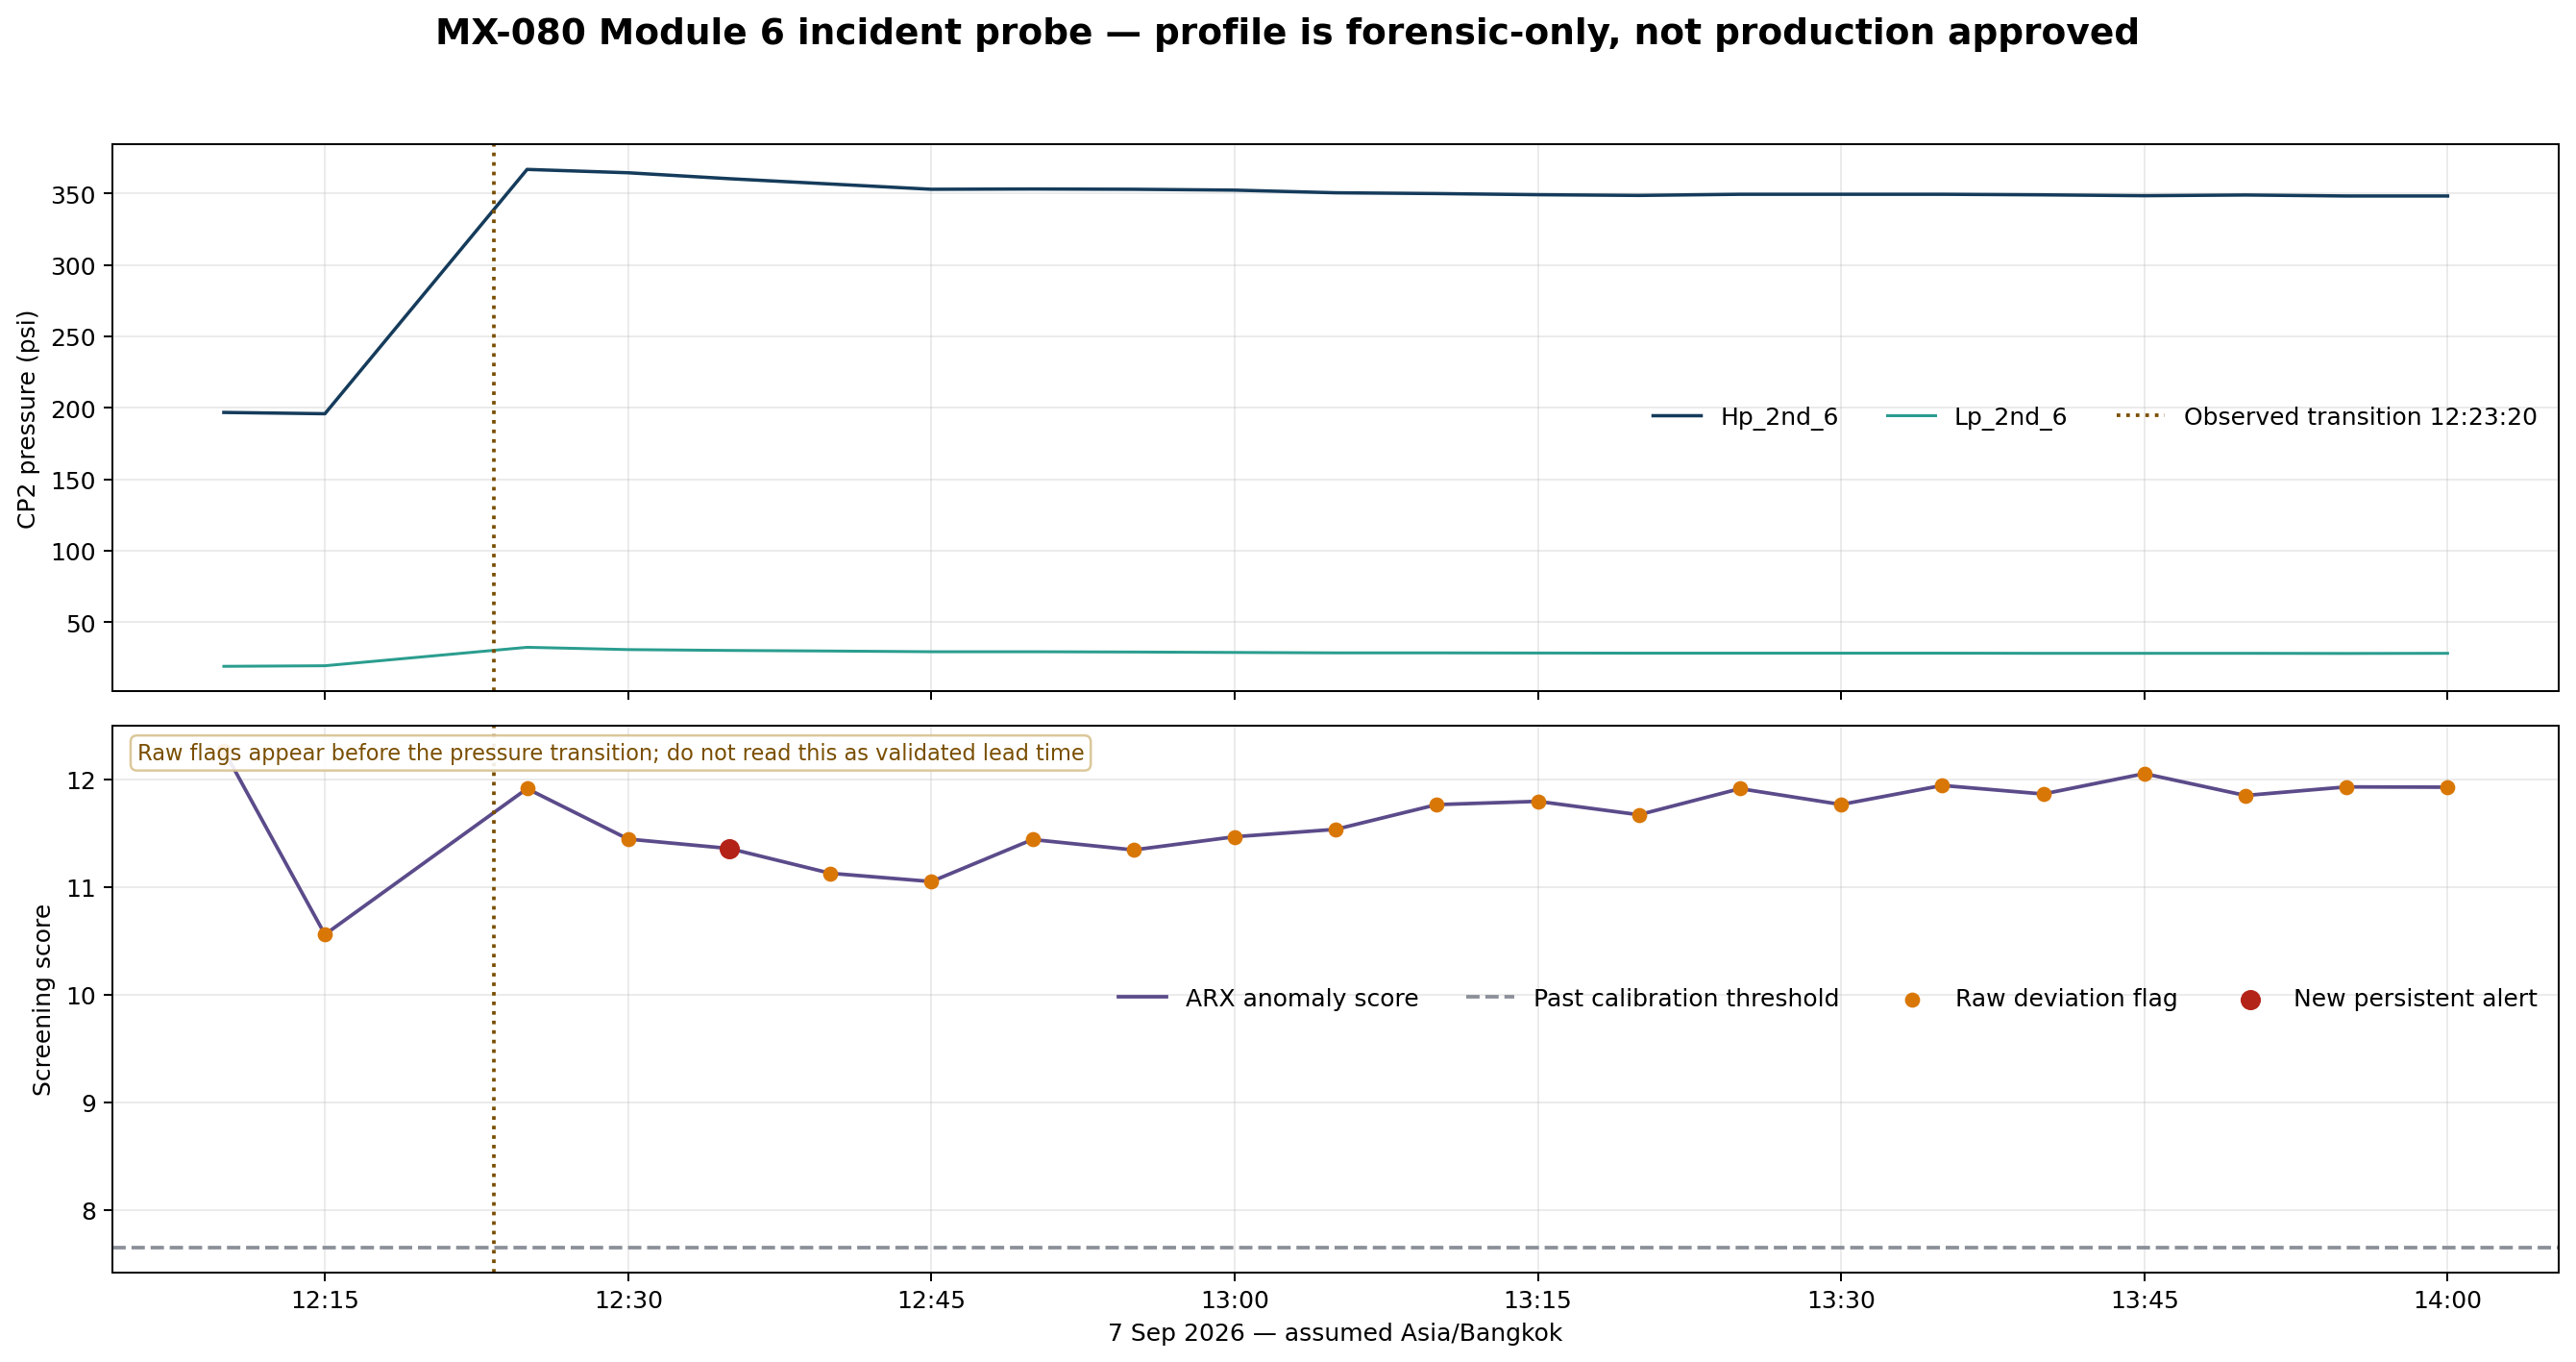

In [5]:
display(Image(filename=summary['figures']['mx080']))

### 6. MX-080 alert episode and ring-buffer availability

In [6]:
display(result['incident_episodes'].round(4))
display(pd.Series(summary['mx080']))
display(result['ring_features'].loc[
    result['ring_features']['timestamp'].between('2026-09-07 12:15', '2026-09-07 12:40'),
    ['timestamp','Hp_2nd_6','Lp_2nd_6','hp2_delta_30s','hp2_delta_120s','hp2_slope_30s','hp2_slope_120s','availability_30s','availability_120s']
].round(3))

,machine_number,module,sv,episode_start,detected_at,detection_delay_minutes,score,threshold
0,080,6,Off,2026-09-07 12:25:00,2026-09-07 12:35:00,10.0,11.3586,7.6507


raw_seconds                                                                       424894
minute_rows                                                                         7190
quality_pass_minutes                                                                7178
quality_fail_minutes                                                                  12
quality_pass_pct                                                               99.833102
quality_rule                           55-60 unique seconds, max within-minute gap <=...
reference_start                                                      2026-09-03 00:05:00
reference_end                                                        2026-09-06 23:55:00
reference_days                                                                         4
profile_status                          INCIDENT_REPLAY_ONLY_INSUFFICIENT_FOR_PRODUCTION
profile_rows                                                                        1151
incident_scored_rows 

,timestamp,Hp_2nd_6,Lp_2nd_6,hp2_delta_30s,hp2_delta_120s,hp2_slope_30s,hp2_slope_120s,availability_30s,availability_120s
1279,2026-09-07 12:15:00,196.4,19.7,0.1,0.1,0.003,0.001,True,True
1280,2026-09-07 12:20:00,177.9,0.0,-16.2,-16.5,-0.540,-0.138,True,True
1281,2026-09-07 12:30:00,365.4,30.9,-0.7,-1.2,-0.023,-0.010,True,True
1282,2026-09-07 12:35:00,361.0,30.4,0.0,-1.2,0.000,-0.010,True,True
1283,2026-09-07 12:40:00,356.7,29.9,-0.2,-1.0,-0.007,-0.008,True,True


### 7. Failure-mode and contract QA

`PASS` หมายถึง replay ทำงานตาม contract; `DATA_QUALITY`, `BLOCKED` และ `INSUFFICIENT_PROFILE` เป็นผลลัพธ์ที่ถูกต้องเมื่อระบบต้องปฏิเสธการ score/activate อย่างปลอดภัย

In [7]:
display(result['failure_tests'])

,test,expected_behavior_met,result_status,evidence
0,valid_batch,True,PASS,valid locked contract scores in shadow
1,feature_version_mismatch,True,FEATURE_VERSION_MISMATCH,rejected before scoring
2,feature_order_mismatch,True,FEATURE_CONTRACT_MISMATCH,rejected before scoring
3,model_checksum_mismatch,True,MODEL_CHECKSUM_MISMATCH,rejected before scoring
4,portable_model_reload,True,PASS,checksum + clean reload
5,missing_core_input,True,DATA_QUALITY,must not become equipment alert
6,stale_input,True,DATA_QUALITY,must not become equipment alert
7,out_of_order_input,True,DATA_QUALITY,quarantined before scoring
8,restart_recovery,True,PASS,one-shot and checkpoint restart outputs must m...
9,automatic_activation,True,BLOCKED,shadow package cannot activate itself


### 8. Locked shadow release manifest

In [8]:
display(pd.Series(result['release_manifest']))

replay_version                                phase07-shadow-replay-v2-hp180
registry_version                            phase07-shadow-registry-v2-hp180
model_key                                                 ARX-Ridge__seed_13
model_selection_source                        inner temporal validation only
model_path                         models/ARX-Ridge__seed_13.portable.joblib
model_sha256               efbb429a40b60fdd34ca7a65f670669f2845fc2060acec...
feature_version                              minute-relative-regime-hp180-v3
profile_version                        machine-module-sv-train-only-hp180-v3
threshold_version                             past-calibration-q995-hp180-v2
hp2_reference_policy       {'qualified_reference_band_psi': [180.0, 230.0...
threshold                                                           7.650716
threshold_source                             separate past calibration q99.5
persistence_windows                                                        3

## Takeaways

1. MX-080 ช่วยงานหลักได้จริง: raw flag rate เปลี่ยนจาก 3.0% ก่อน transition เป็น 100% หลัง transition และ persistent alert เปิดเวลา 12:35 โดยไม่ได้ใช้ incident เลือก model/threshold
2. Raw flag ก่อน 12:23 อาจเป็น precursor หรือ profile mismatch; เพราะไม่มี confirmed onset จึงห้ามเรียกว่า validated lead time
3. ผลนี้แสดง incident sensitivity เพียงหนึ่งเหตุการณ์ ไม่ใช่ recall หรือ fault accuracy
4. Primary replay รุ่น hp180 มี 36 persistent alerts เทียบกับ 37 ในรุ่น 200 psi; alert ที่ลดลงหนึ่งครั้งอยู่ที่ MX058 แต่ MX058/MX082 ยังมี burden สูงสุด จึงต้อง review alert budget และ state/profile mismatch ก่อนส่งช่างจริง
5. Model artifact รุ่นเดิมมี pickle class path แบบ `__main__`; replay นี้ re-export เป็น portable artifact พร้อม checksum และทดสอบ clean reload แล้ว
6. Missing/stale/out-of-order/version/order/checksum cases ถูกออกแบบให้หยุดเป็น data/contract status ไม่ออก equipment alert
7. MX-080 profile 4 วันยังใช้ Production ไม่ได้ และไม่มี automatic profile activation
8. Phase 7 ยังปิดไม่ได้จนกว่าจะมี exact rollback target, approved alert budget, timezone/unit/service epoch และ server/MySQL integration replay

### Production decision

สถานะที่ถูกต้องคือ `PASS_WITH_PRODUCTION_BLOCKERS`: พร้อมส่งต่อให้ Server owner ทำ integration ใน shadow environment แต่ยังไม่พร้อม technician advisory หรือ production activation.